# 03 — Predictive models: churn, 90-day CLV, coupon propensity

**Questions:** which active households will stop buying, how much will each household spend next quarter,
and who will redeem a coupon if we send a campaign?

Everything here is produced by two scripts; this notebook only reads their outputs:
- `python -m src.models.train` — out-of-time datasets, rolling backtest selection, test evaluation, plots, SHAP, MLflow
- `python -m src.pipelines.score` — scores all 2,500 households as of day 711 → `c360.household_predictions`

### Evaluation design (why the numbers can be trusted)
- **Out-of-time only.** Features use data up to a cutoff day T; the label is what happens in (T, T + horizon].
  No random split: every score is on a future the model never saw.
- **No label overlap.** Asserts in `src/models/datasets.py` guarantee training labels end before validation
  starts, and validation labels end before test starts. (A first version had 90-day labels from cutoff 440 running
  into the validation window at 470/500 — caught and fixed.)
- **Selection on a rolling backtest** (3–7 folds), not on one validation cutoff: one cutoff has ~120 churners,
  too few to separate models (bootstrap PR-AUC intervals overlapped almost completely).
- **Test cutoff is touched once**, after every choice is made. Test metrics carry 95% bootstrap intervals.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from src.models.datasets import TASKS, backtest_folds

pd.set_option("display.width", 220)
results = {r["task"]: r for r in json.loads((ROOT / "reports" / "model_results.json").read_text())}
FIG = ROOT / "reports" / "figures"
pd.DataFrame([{"task": t.name, "horizon_days": t.horizon, "train_cutoffs": t.train_cutoffs,
               "valid_cutoff": t.valid_cutoff, "test_cutoff": t.test_cutoff,
               "backtest_folds": [c for _, c in backtest_folds(t)], "target": t.description} for t in TASKS.values()])

,task,horizon_days,train_cutoffs,valid_cutoff,test_cutoff,backtest_folds,target
0,churn,60,"(260, 290, 320, 350, 380, 410, 440, 470, 500)",560,620,"[350, 380, 410, 440, 470, 500, 560]",Active household (bought in last 60 days) make...
1,clv,90,"(230, 260, 290, 320, 350, 380, 410)",500,590,"[350, 380, 410, 500]",Customer spend (customer_paid) in the next 90 ...
2,coupon_propensity,90,"(230, 260, 290, 320, 350, 380)",470,560,"[350, 380, 470]",Household receiving a campaign in the next 90 ...


In [2]:
def show(task):
    r = results[task]
    print("selected by backtest:", r["best"], "| decision threshold:", r["threshold"])
    bt = pd.DataFrame(r["backtest"]).T
    display(bt)
    display(pd.DataFrame(r["test"]).T)

## 1. Churn (active households, 60-day horizon, ~6% positive)

Candidates: logistic regression (C = 0.1, tuned on the backtest), LightGBM, XGBoost and the probability
average of logistic regression + XGBoost.

In [3]:
show("churn")

selected by backtest: logreg_xgb_average | decision threshold: 0.17781120009773693


,mean_pr_auc,std_pr_auc,folds_won,per_fold
logistic_regression,0.304521,0.031334,1,"[0.3, 0.313, 0.275, 0.281, 0.356, 0.341, 0.266]"
lightgbm,0.292745,0.04926,0,"[0.253, 0.305, 0.225, 0.282, 0.377, 0.343, 0.263]"
xgboost,0.298398,0.050157,0,"[0.259, 0.31, 0.234, 0.271, 0.383, 0.356, 0.275]"
logreg_xgb_average,0.318779,0.042818,6,"[0.304, 0.335, 0.266, 0.293, 0.392, 0.363, 0.278]"


,roc_auc,pr_auc,brier,f1,threshold,precision,recall,lift_top10,positive_rate,pr_auc_ci
logistic_regression,0.8614,0.3284,0.0489,0.4094,0.1778,0.3812,0.442,5.1518,0.0615,"[0.2604, 0.4034]"
lightgbm,0.8803,0.3488,0.0471,0.394,0.1778,0.335,0.4783,5.2244,0.0615,"[0.2778, 0.4357]"
xgboost,0.8827,0.3465,0.047,0.431,0.1778,0.3571,0.5435,5.7323,0.0615,"[0.2741, 0.4327]"
logreg_xgb_average,0.8789,0.3655,0.0472,0.4174,0.1778,0.3661,0.4855,5.2969,0.0615,"[0.2927, 0.444]"


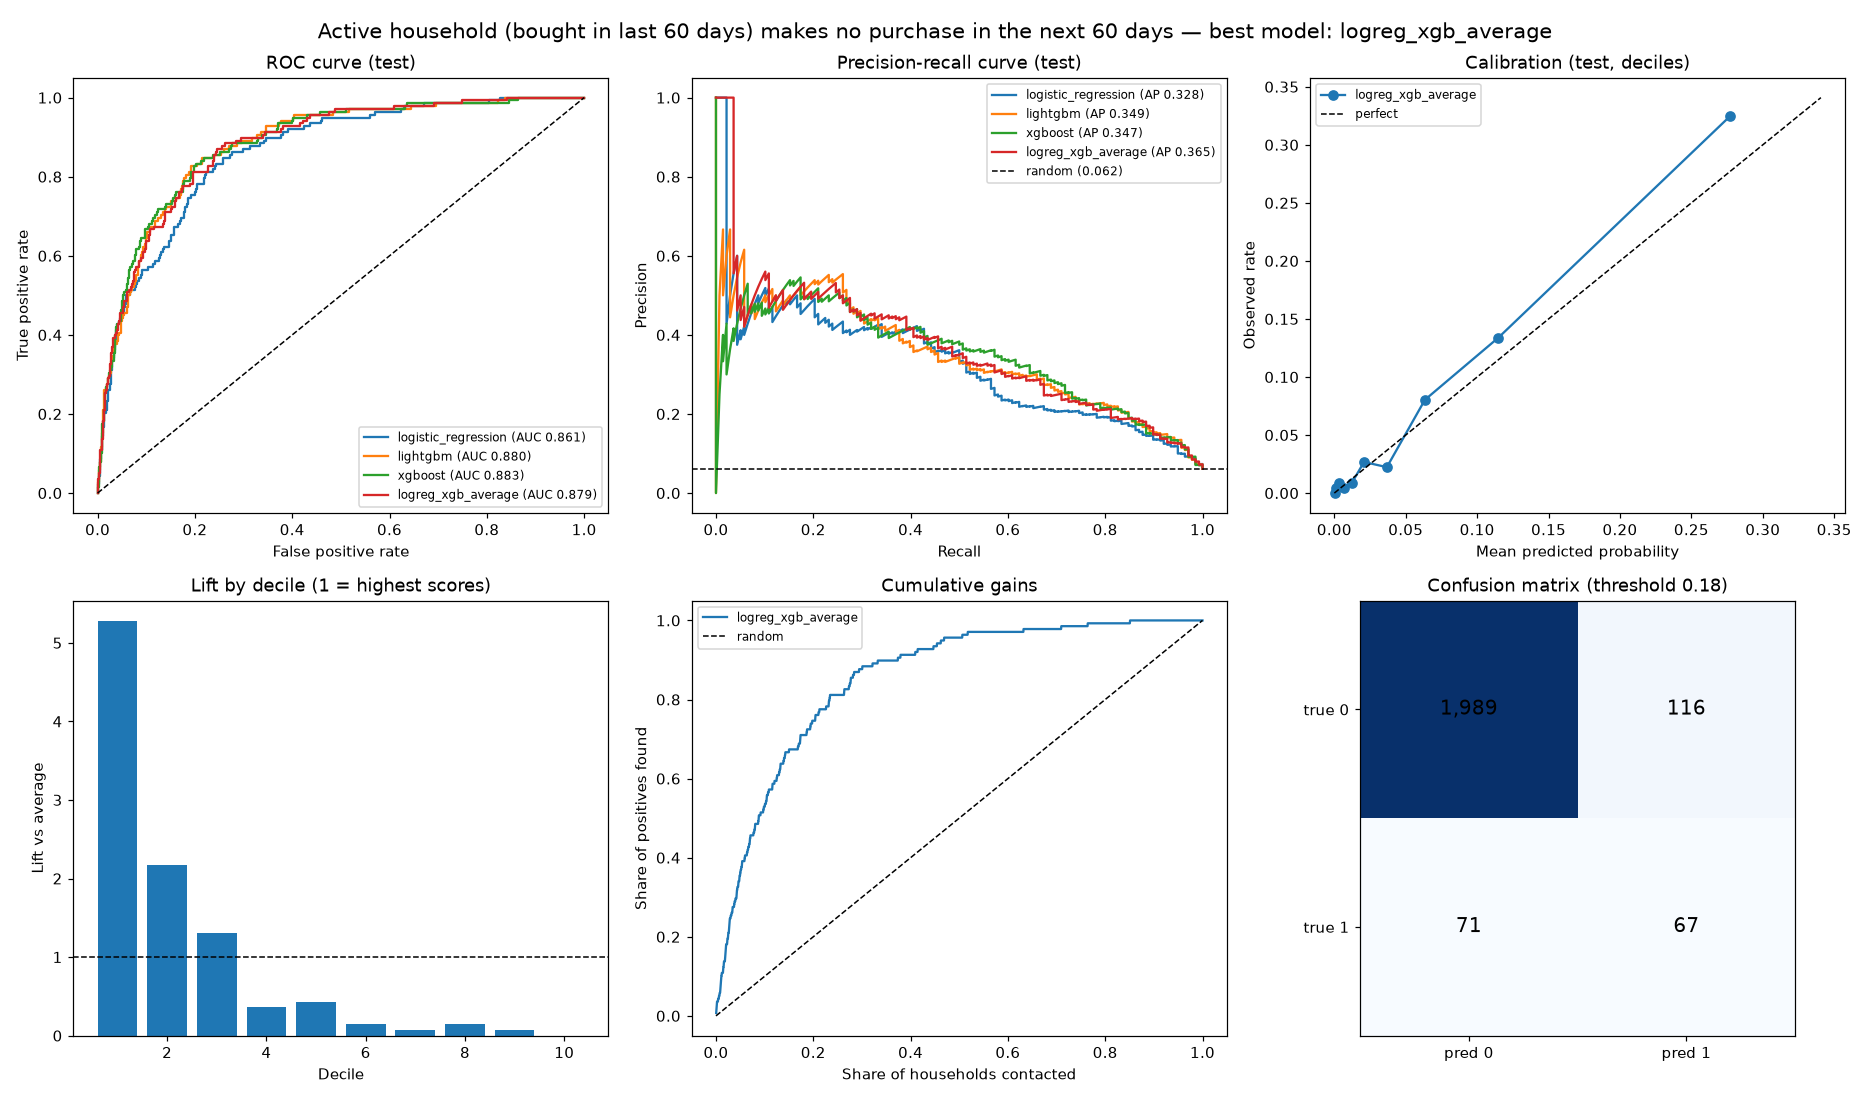

In [4]:
display(Image(FIG / "churn_diagnostics.png"))

**Reading the plots**
- The single models are statistically tied (test PR-AUC 0.33–0.35, overlapping intervals). The linear and tree
  models win *different* folds, so their errors differ — the average wins **6 of 7** backtest folds and is also best
  on test (PR-AUC 0.366 vs 0.062 random; ROC-AUC 0.88).
- **Lift:** the top 10% of scores hold 5.3× the average churn rate; contacting 20% of active households reaches
  roughly 75% of churners (cumulative gains).
- **Calibration:** close to the diagonal; slightly low in the top bins (0.28 predicted vs 0.33 observed) because
  the test period's churn rate (6.15%) is a bit higher than training (5.8%). Ranking is unaffected.
- **Threshold** (0.18) maximises F1 on pooled out-of-fold predictions — never on test. In practice marketing
  should pick the cut by budget using the gains curve.

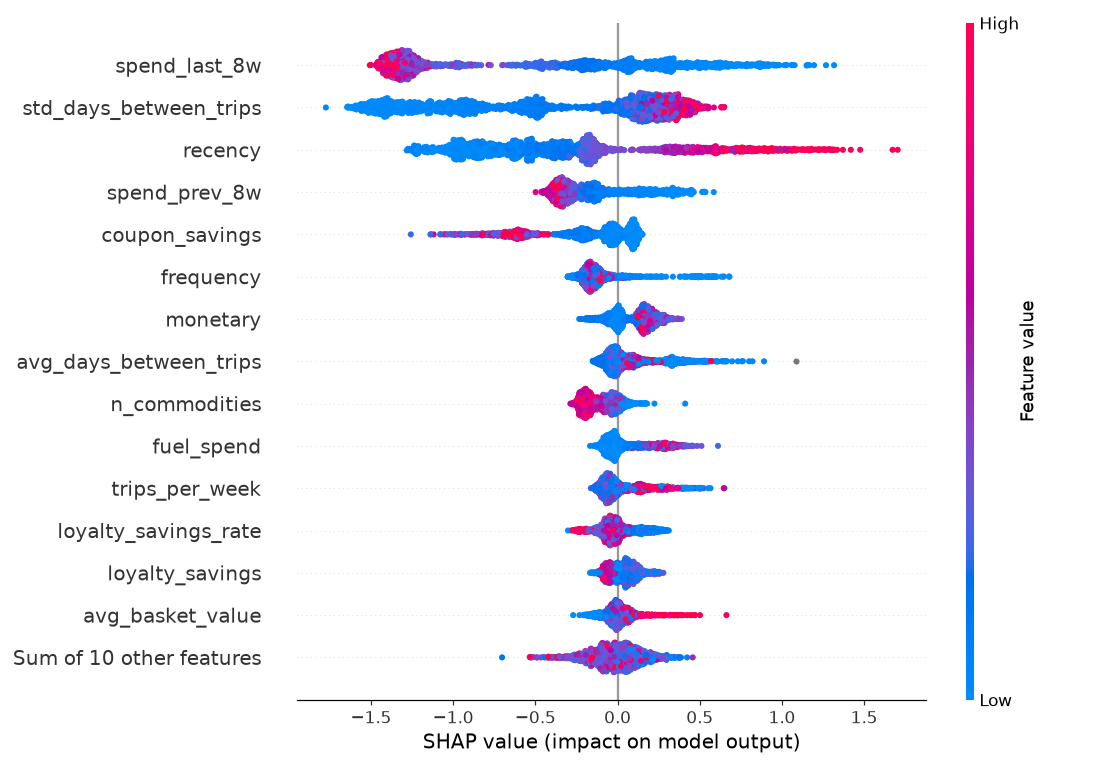

In [5]:
display(Image(FIG / "churn_shap_beeswarm.png"))

**What drives churn** (SHAP on the XGBoost half of the average): low spend in the last 8 weeks, long time since the
last trip, and — the least obvious signal — **irregular trip intervals** (`std_days_between_trips`). Households
that use coupons and loyalty savings churn less.

## 2. Customer value: spend in the next 90 days

Candidates: ridge on signed-log features, LightGBM and XGBoost with a **Tweedie** objective, and a naive
run-rate baseline (last 8 weeks scaled to 90 days).

In [6]:
show("clv")

selected by backtest: lightgbm_tweedie | decision threshold: None


,mean_mae,std_mae,folds_won,per_fold
ridge_log,235.294264,1.960079,0,"[236.467, 231.905, 236.247, 236.558]"
lightgbm_tweedie,169.13677,3.35197,3,"[166.575, 168.283, 174.833, 166.855]"
xgboost_tweedie,169.352578,3.47422,1,"[167.242, 169.034, 175.082, 166.052]"


,mae,rmse,r2,spearman,total_bias,top_decile_bias,min_pred,mae_ci
ridge_log,235.925,343.3165,0.5912,0.7796,-0.0773,-0.1915,-579.3491,"[226.6797, 246.301]"
lightgbm_tweedie,166.5454,255.2362,0.7741,0.8384,-0.0697,-0.0635,8.1059,"[159.6709, 173.9239]"
xgboost_tweedie,166.5559,254.3921,0.7756,0.8405,-0.0851,-0.0829,5.5754,"[159.2278, 173.915]"
naive_run_rate,179.5867,271.7836,0.7438,0.813,-0.0709,0.0525,0.0,"[171.5406, 187.3216]"


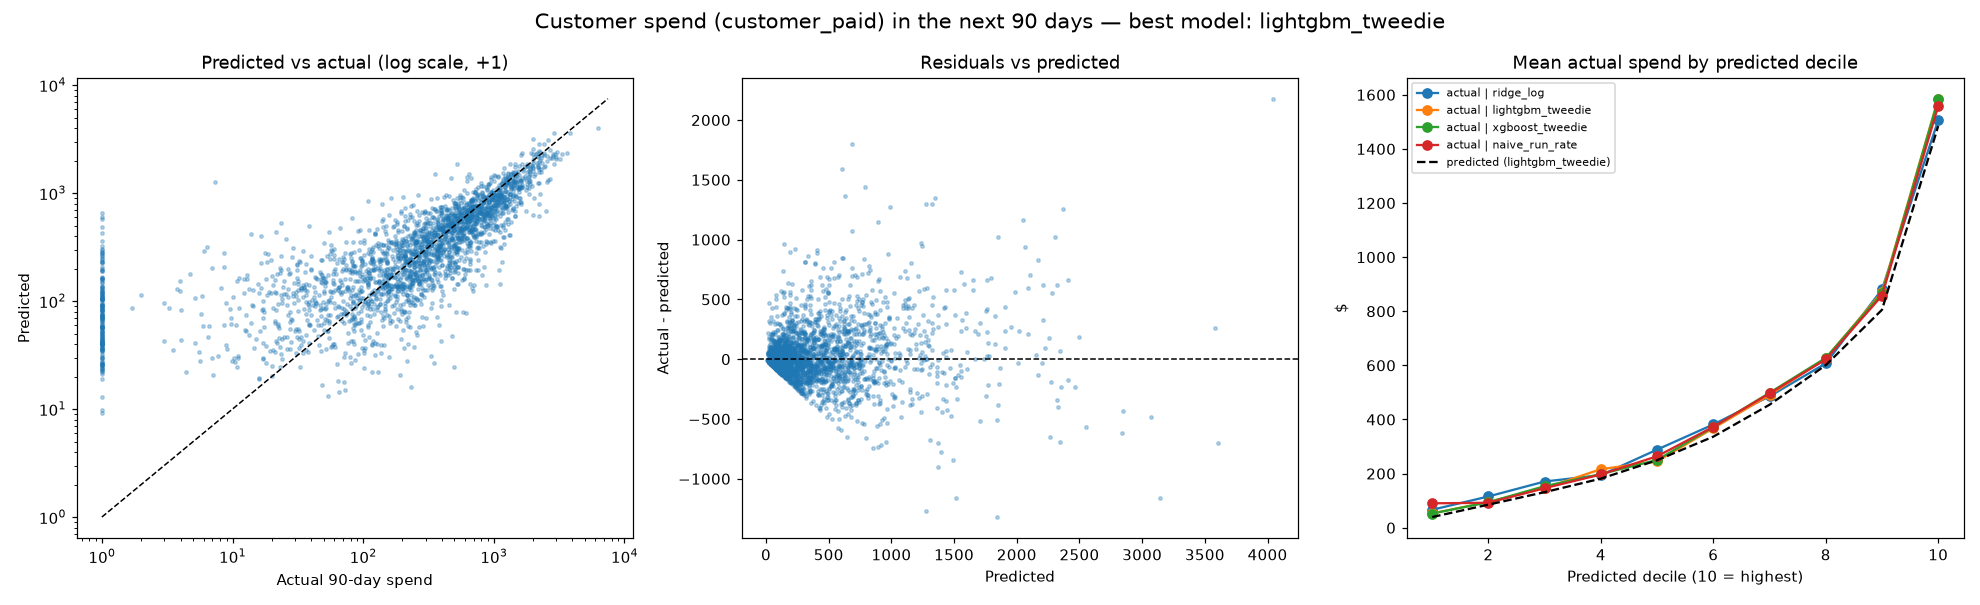

In [7]:
display(Image(FIG / "clv_diagnostics.png"))

**Why Tweedie** (backtest comparison in the assumptions log, A19): squared error predicted *negative* spend
(down to −$161); L1 and log-target models under-stated total value by 4–17%. Tweedie never goes below zero,
has near-zero total bias on the backtest and the lowest error.

**Reading the plots**
- Test MAE $166.5 (95% CI 160–174) vs naive $179.6 — a 7% improvement; R² 0.77; Spearman 0.84.
  The naive baseline is strong because grocery spend is habitual; the model's gain is real but modest, and we say so.
- Predicted deciles track actual deciles closely.
- **Total bias −7% on test, the same as the naive baseline**: the test quarter simply spent more than history.
  Without calendar dates (A01) seasonality cannot be modelled.
- **Known limitation:** the 6.8% of households that spend $0 still get $10–600 predicted. A hurdle model
  (P(buy) × spend | buy) would address it; left as future work.

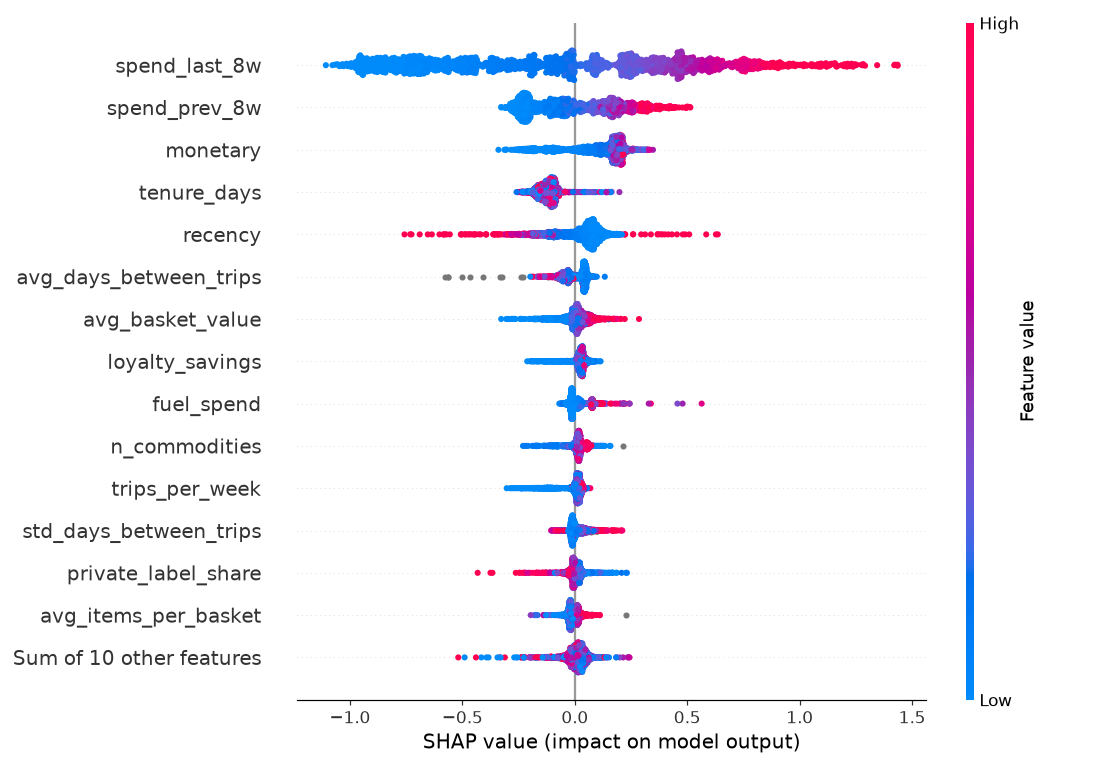

In [8]:
display(Image(FIG / "clv_shap_beeswarm.png"))

## 3. Coupon redemption propensity (households receiving a campaign in the next 90 days)

Candidates as for churn; logistic regression uses **C = 0.01**. With weaker regularisation the correlated spend
features flip sign and the top decile was over-confident (0.84 predicted vs 0.72 observed, outside the ±0.08 interval).

In [9]:
show("coupon_propensity")

selected by backtest: logreg_xgb_average | decision threshold: 0.15315473249986616


,mean_pr_auc,std_pr_auc,folds_won,per_fold
logistic_regression,0.433928,0.053424,1,"[0.392, 0.401, 0.509]"
lightgbm,0.388831,0.060013,0,"[0.332, 0.362, 0.472]"
xgboost,0.399323,0.058783,0,"[0.344, 0.373, 0.481]"
logreg_xgb_average,0.441636,0.044777,2,"[0.404, 0.416, 0.505]"


,roc_auc,pr_auc,brier,f1,threshold,precision,recall,lift_top10,positive_rate,pr_auc_ci
logistic_regression,0.8296,0.5982,0.1144,0.5324,0.1532,0.3964,0.8107,3.7723,0.1961,"[0.536, 0.6592]"
lightgbm,0.8106,0.5737,0.119,0.5104,0.1532,0.3849,0.7572,3.4406,0.1961,"[0.5091, 0.6345]"
xgboost,0.8177,0.586,0.1163,0.5089,0.1532,0.3811,0.7654,3.4821,0.1961,"[0.5249, 0.6449]"
logreg_xgb_average,0.8328,0.6056,0.1125,0.5198,0.1532,0.3893,0.7819,3.6479,0.1961,"[0.5425, 0.6641]"


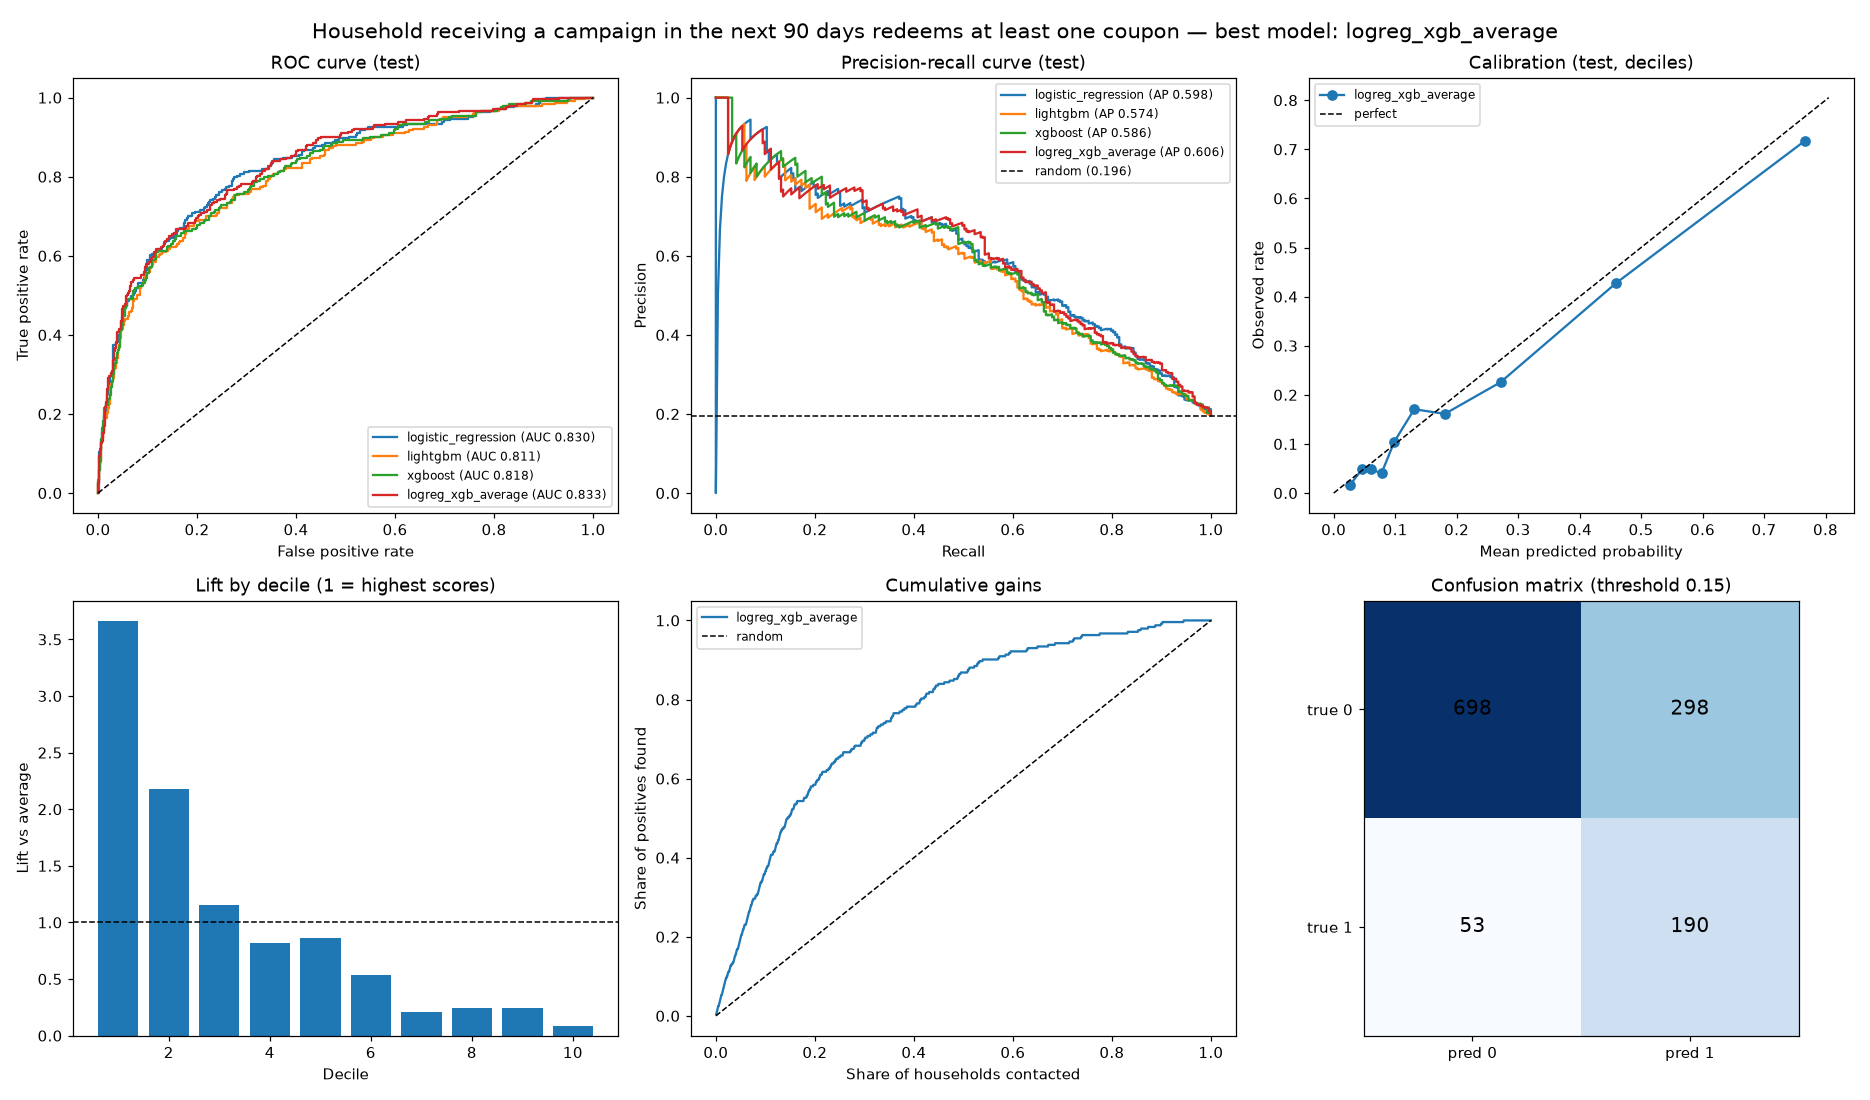

In [10]:
display(Image(FIG / "coupon_propensity_diagnostics.png"))

**Reading the plots**
- The average again wins the backtest (PR-AUC 0.442) and test (0.606, ROC-AUC 0.83, top-decile lift 3.6×).
- Test PR-AUC is higher than the backtest mostly because the **base rate rose** (13.5% → 19.6%); PR-AUC moves
  with prevalence, so compare lift, not raw PR-AUC, across periods.
- Calibration is reasonable; slightly high in the upper bins.
- **Selection bias (A16):** the model learns only from households marketing chose to target (mostly heavy
  shoppers). Scores for never-targeted households are an extrapolation and are flagged in the output.

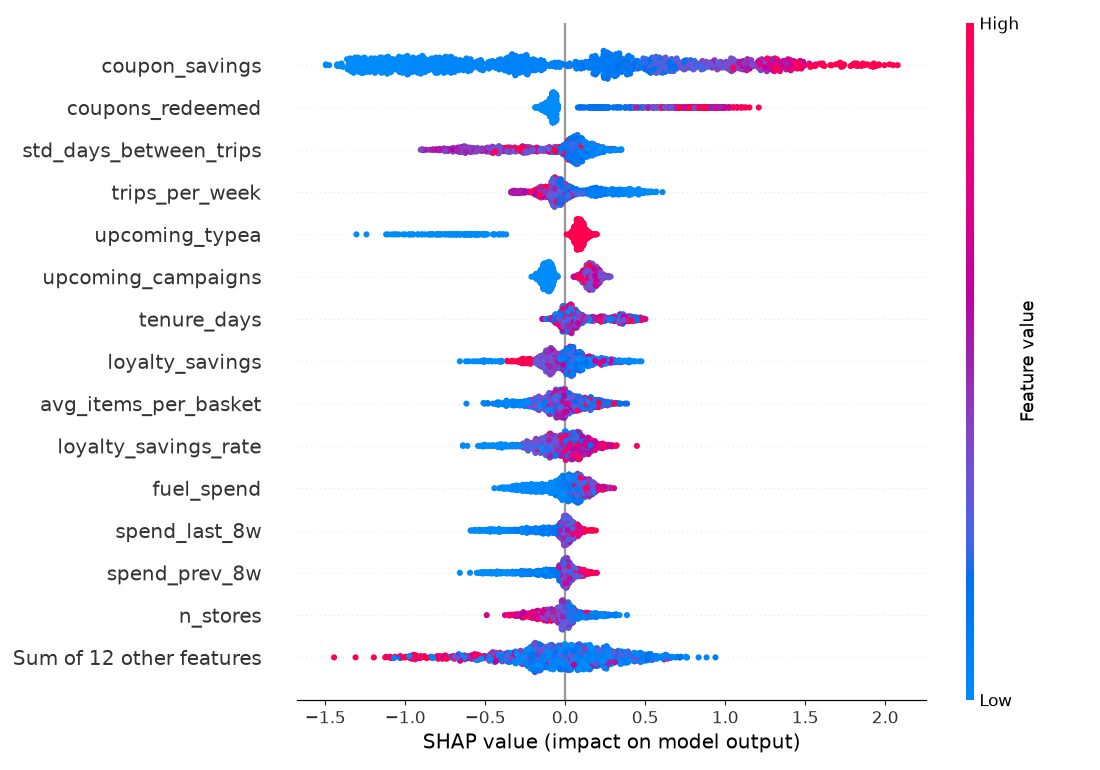

In [11]:
display(Image(FIG / "coupon_propensity_shap_beeswarm.png"))

## 4. Scores for every household (as of day 711)

In [12]:
pred = pd.read_parquet(ROOT / "data" / "processed" / "household_predictions.parquet")
seg = pd.read_parquet(ROOT / "data" / "processed" / "household_segments.parquet")[["household_key", "cluster_name"]]
d = pred.merge(seg, on="household_key")
display(d.churn_risk_band.value_counts())
d.groupby("cluster_name").agg(households=("household_key", "size"), share_active=("is_active", "mean"),
                              churn_probability=("churn_probability", "mean"),
                              predicted_spend_90d=("predicted_spend_90d", "mean"),
                              spend_at_risk_90d=("spend_at_risk_90d", "sum"),
                              coupon_redeem_probability=("coupon_redeem_probability", "mean")).round(3)

churn_risk_band
Low       1558
Medium     447
Lapsed     255
High       240
Name: count, dtype: int64[pyarrow]

,households,share_active,churn_probability,predicted_spend_90d,spend_at_risk_90d,coupon_redeem_probability
cluster_name,,,,,,
Frequent Top-Up Shoppers,630,0.992,0.036,320.967,4469.815,0.043
Lapsing Low-Value,416,0.587,0.251,83.770,5324.690,0.008
Occasional Stock-Up Shoppers,683,0.887,0.086,335.888,12279.123,0.046
VIP Regulars,771,0.999,0.006,1021.044,2786.770,0.171


In [13]:
# Who to call first: active, high churn risk, ranked by spend at risk
d[d.churn_risk_band == "High"].nlargest(10, "spend_at_risk_90d")[
    ["household_key", "cluster_name", "churn_probability", "predicted_spend_90d", "spend_at_risk_90d"]].round(2)

,household_key,cluster_name,churn_probability,predicted_spend_90d,spend_at_risk_90d
148,149,Occasional Stock-Up Shoppers,0.41,629.80,256.87
1015,1016,Occasional Stock-Up Shoppers,0.27,470.72,126.50
930,931,Occasional Stock-Up Shoppers,0.18,637.68,115.51
1090,1091,Occasional Stock-Up Shoppers,0.42,276.26,115.12
2250,2251,Occasional Stock-Up Shoppers,0.39,288.28,111.50
1573,1574,Occasional Stock-Up Shoppers,0.25,401.34,101.25
1701,1702,Occasional Stock-Up Shoppers,0.24,375.08,91.07
1104,1105,Occasional Stock-Up Shoppers,0.31,291.42,89.72
1035,1036,Occasional Stock-Up Shoppers,0.37,227.49,83.36
85,86,Occasional Stock-Up Shoppers,0.20,402.24,79.60


## Summary

| Task | Selected model | Test result (95% CI) | Business reading |
|---|---|---|---|
| Churn (60 d) | LogReg + XGBoost average | PR-AUC 0.366 (0.29–0.44), ROC-AUC 0.88 | Top 10% of scores = 5.3× churn rate |
| Spend next 90 d | LightGBM Tweedie | MAE $166.5 (160–174), R² 0.77 | 7% better than the run-rate rule, never negative |
| Coupon redemption | LogReg + XGBoost average | PR-AUC 0.606 (0.54–0.66), ROC-AUC 0.83 | Top 10% = 3.6× redemption rate |

The segments agree with the models: Lapsing Low-Value households average 25% churn probability, VIP Regulars 0.6%.
All runs are tracked in MLflow: `mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db`.